In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

N_EVENTS = 1000
N_PARTICLES = 144
FILES = {"minbias": "data/minbias.csv", "ttbar": "data/ttbar.csv", "hllhc-z": "data/hllhc-z.csv"}
COLORS = {"minbias": "#2a78d6", "ttbar": "#eb6834", "hllhc-z": "#1baf7a"}
FEATURES = ["pt", "eta", "phi", "pid", "reliso", "shoshape"]

dfs = {name: pd.read_csv(path, skipinitialspace=True, nrows=N_EVENTS * N_PARTICLES)
       for name, path in FILES.items()}

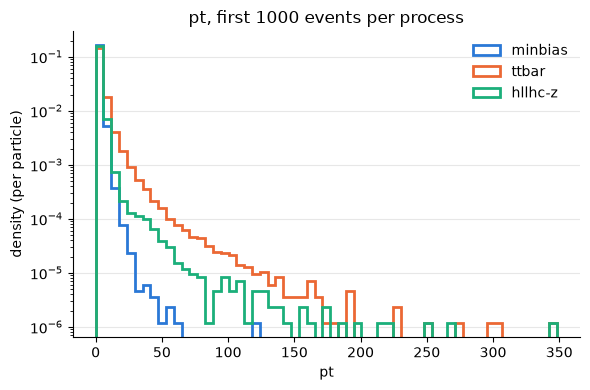

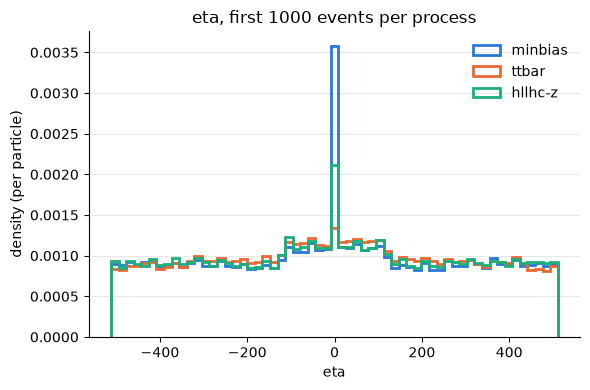

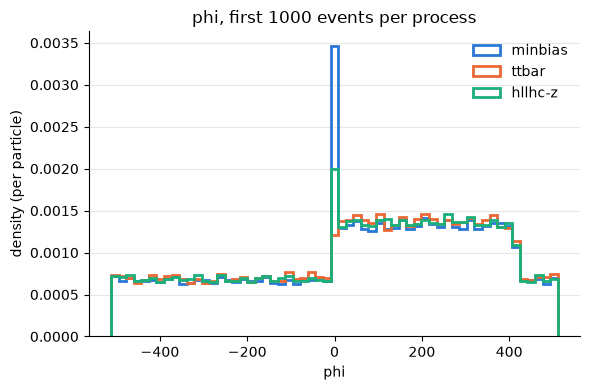

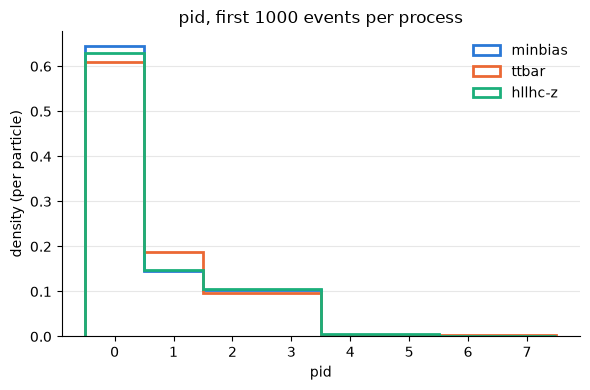

skipping reliso: constant (0) in all processes
skipping shoshape: constant (0) in all processes


In [5]:
def bins_for(feature):
    values = np.concatenate([df[feature].to_numpy() for df in dfs.values()])
    if feature == "pid":  # discrete: one bin per id
        return np.arange(values.min(), values.max() + 2) - 0.5
    return np.linspace(values.min(), values.max(), 60)


for feature in FEATURES:
    if all(df[feature].nunique() == 1 for df in dfs.values()):
        print(f"skipping {feature}: constant ({dfs['minbias'][feature].iloc[0]}) in all processes")
        continue

    fig, ax = plt.subplots(figsize=(6, 4))
    bins = bins_for(feature)
    for name, df in dfs.items():
        ax.hist(df[feature], bins=bins, density=True, histtype="step", linewidth=2,
                color=COLORS[name], label=name)
    if feature == "pt":
        ax.set_yscale("log")
    ax.set_xlabel(feature)
    ax.set_ylabel("density (per particle)")
    ax.set_title(f"{feature}, first {N_EVENTS} events per process")
    ax.legend(frameon=False)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()